# Looking at diversity in the main text

Zherui put the full article bodies for the scored Medium and Substack posts on OneDrive. Same 350k posts per platform. We pulled the text out of the zips and built a few simple diversity numbers, then joined them back to the detector scores.

For each post we get things like how many unique words it uses (TTR), unigram entropy, hapax rate, etc. For each month we also take a sample of posts and ask how different they look from each other on shared words.

December 2022 is still the break. We call a post AI-flagged when `P_AI` is at least 0.5. The monthly files are in `data/diversity/`.


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

ROOT = Path("/Users/kofibadu/Desktop/cap folder")
DIV = ROOT / "data" / "diversity"
CUT = "2022-12"
COLORS = {"medium": "#c45c26", "substack": "#1b3a4b"}


def load_month(platform: str) -> pd.DataFrame:
    df = pd.read_csv(DIV / f"{platform}_monthly_diversity.csv")
    df["platform"] = platform
    df["period"] = np.where(df["year_month"] >= CUT, "post", "pre")
    return df


def load_posts(platform: str, usecols=None) -> pd.DataFrame:
    path = DIV / f"{platform}_post_diversity.csv"
    df = pd.read_csv(path, usecols=usecols)
    df["platform"] = platform
    return df


month = pd.concat([load_month("medium"), load_month("substack")], ignore_index=True)
print(month.groupby("platform")["n"].sum().astype(int).to_string())
print("months per platform:", month.groupby("platform").size().to_dict())


platform
medium      350000
substack    350000
months per platform: {'medium': 81, 'substack': 81}


## How the monthly lines move

Entropy and TTR are about vocabulary *inside* one post. The semantic line is about how far apart posts are from each other that month. If that line goes up, posts look less alike.


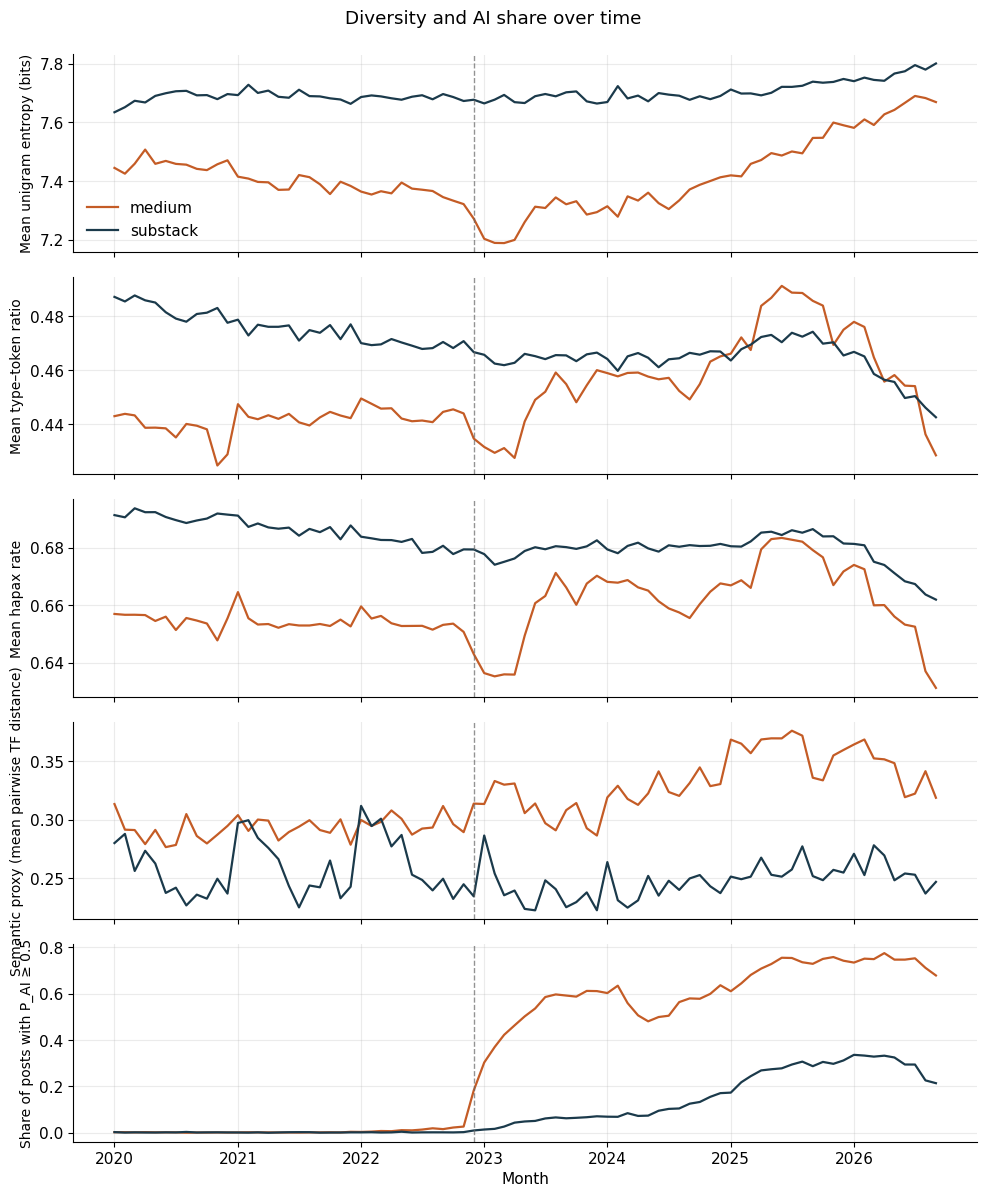

In [ ]:
metrics = [
    ("mean_entropy", "Mean unigram entropy (bits)"),
    ("mean_ttr", "Mean type–token ratio"),
    ("mean_hapax_rate", "Mean hapax rate"),
    ("semantic_mean_pairwise_distance", "Between-post distance (TF)"),
    ("share_ai", "Share AI-flagged"),
]

fig, axes = plt.subplots(len(metrics), 1, figsize=(10, 12), sharex=True)
for ax, (col, title) in zip(axes, metrics):
    for platform, g in month.groupby("platform"):
        ax.plot(pd.to_datetime(g["year_month"]), g[col], label=platform, color=COLORS[platform], lw=1.6)
    ax.axvline(pd.Timestamp("2022-12-01"), color="#666", ls="--", lw=1, alpha=0.7)
    ax.set_ylabel(title, fontsize=10)
axes[0].legend(frameon=False)
axes[-1].set_xlabel("Month")
fig.suptitle("Diversity over time", y=0.995)
fig.tight_layout()
plt.show()


## Before vs after ChatGPT, and does it track AI share?

Just averaging the monthly numbers pre/post, and checking how tightly they move with the AI share line.


In [ ]:
cols = [
    "mean_entropy", "mean_ttr", "mean_hapax_rate",
    "semantic_mean_pairwise_distance", "share_ai", "mean_token_count",
]
summary = (
    month.groupby(["platform", "period"])[cols]
    .mean()
    .round(4)
    .reindex(pd.MultiIndex.from_product([["medium", "substack"], ["pre", "post"]]))
)
display(summary)

print("corr with monthly AI share")
for platform, g in month.groupby("platform"):
    print(platform)
    print(g[["share_ai"] + cols[:-2]].corr().loc["share_ai"].drop("share_ai").round(3).to_string())
    print()


mean_entropy  mean_ttr  mean_hapax_rate  \
medium   pre         7.4045    0.4416           0.6544   
         post        7.4234    0.4593           0.6622   
substack pre         7.6870    0.4760           0.6865   
         post        7.7097    0.4642           0.6791   

               semantic_mean_pairwise_distance  share_ai  mean_token_count  
medium   pre                            0.2933    0.0051          917.4470  
         post                           0.3340    0.6161          867.7755  
substack pre                            0.2596    0.0016         1085.1920  
         post                           0.2478    0.1695         1166.6834

\nPearson corr of monthly share_ai with diversity metrics
medium
mean_entropy                       0.320
mean_ttr                           0.700
mean_hapax_rate                    0.495
semantic_mean_pairwise_distance    0.797

substack
mean_entropy                       0.711
mean_ttr                          -0.487
mean_hapax_rate                   -0.415
semantic_mean_pairwise_distance    0.012



## AI-flagged vs human-flagged posts

TTR gets weird with short posts, so we also split by length. If AI writing were flatter, we would expect lower entropy and TTR inside the same length bin.


In [ ]:
usecols = [
    "ai_flag", "entropy", "ttr", "hapax_rate", "entropy_norm",
    "token_count", "type_count", "P_AI",
]
posts = pd.concat([
    load_posts("medium", usecols=usecols),
    load_posts("substack", usecols=usecols),
], ignore_index=True)
posts = posts[posts["ai_flag"].isin([0, 1])].copy()
posts["ai_flag"] = posts["ai_flag"].astype(int)

overall = (
    posts.groupby(["platform", "ai_flag"])[["entropy", "ttr", "hapax_rate", "entropy_norm", "token_count"]]
    .agg(["count", "mean"])
)
display(overall.round(4))

bins = [0, 300, 600, 1000, 2000, 10**9]
labels = ["0-300", "300-600", "600-1k", "1k-2k", "2k+"]
posts["len_bin"] = pd.cut(posts["token_count"], bins=bins, labels=labels, right=False)

binned = (
    posts.groupby(["platform", "len_bin", "ai_flag"], observed=True)[["entropy", "ttr", "hapax_rate"]]
    .mean()
    .round(4)
)
display(binned)


entropy             ttr         hapax_rate          \
                   count    mean   count    mean      count    mean   
platform ai_flag                                                      
medium   0        220982  7.3920  220982  0.4444     220982  0.6558   
         1        129018  7.4791  129018  0.4649     129018  0.6644   
substack 0        312975  7.6963  312975  0.4686     312975  0.6826   
         1         37025  7.7554   37025  0.4706      37025  0.6763   

                 entropy_norm         token_count             
                        count    mean       count       mean  
platform ai_flag                                              
medium   0             220982  0.9007      220982   919.3207  
         1             129018  0.9074      129018   853.4782  
substack 0             312975  0.9029      312975  1136.0002  
         1              37025  0.9060       37025  1139.6712

entropy     ttr  hapax_rate
platform len_bin ai_flag                             
medium   0-300   0         6.5517  0.5737      0.7045
                 1         6.6688  0.5984      0.7287
         300-600 0         7.0961  0.4924      0.6758
                 1         7.1851  0.5084      0.6902
         600-1k  0         7.5112  0.4300      0.6527
                 1         7.6077  0.4510      0.6606
         1k-2k   0         7.8560  0.3711      0.6266
                 1         7.9712  0.3864      0.6187
         2k+     0         8.2557  0.2932      0.5867
                 1         8.3778  0.3025      0.5688
substack 0-300   0         6.7053  0.6221      0.7389
                 1         6.7419  0.6294      0.7479
         300-600 0         7.2736  0.5371      0.7077
                 1         7.3070  0.5400      0.7097
         600-1k  0         7.7088  0.4701      0.6849
                 1         7.7526  0.4769      0.6835
         1k-2k   0         8.0809  0.4101      0.6628
                 1         8.1219  0.4149      0.6512
         2k+     0         8.5031  0.3289      0.6244
                 1         8.5928  0.3220      0.5933

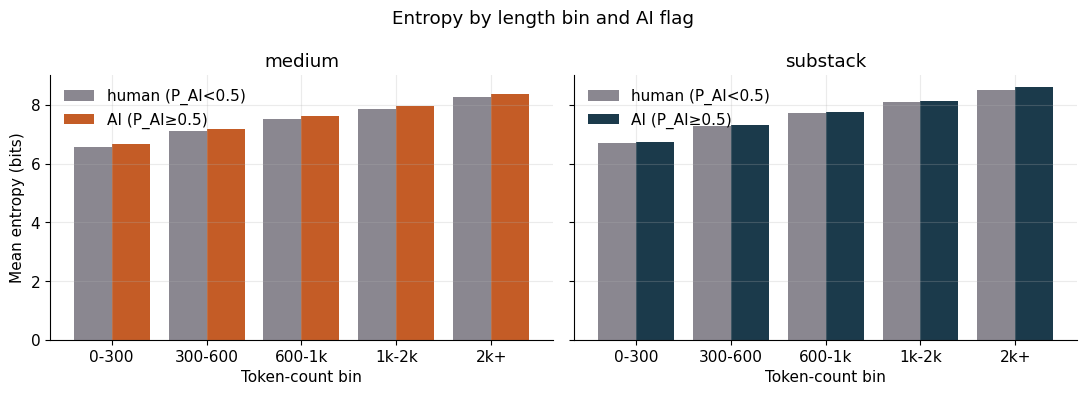

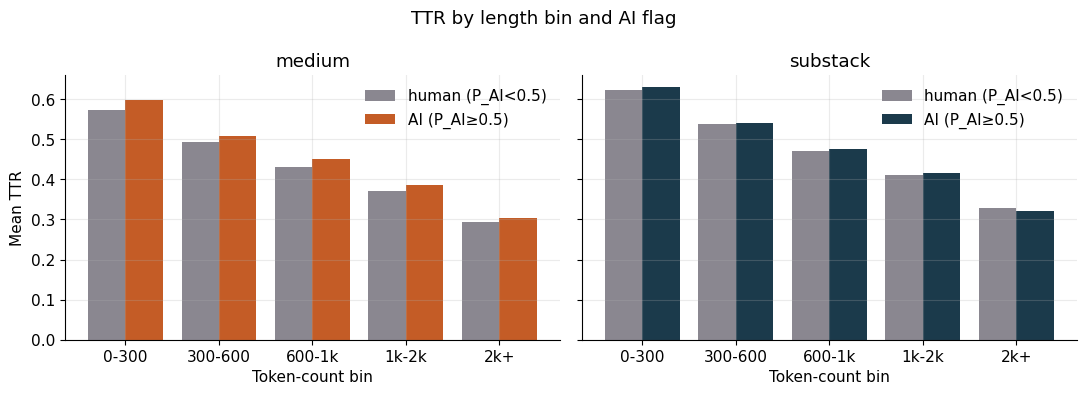

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, platform in zip(axes, ["medium", "substack"]):
    g = posts[posts["platform"] == platform]
    means = g.groupby(["len_bin", "ai_flag"], observed=True)["entropy"].mean().unstack("ai_flag")
    means.plot(kind="bar", ax=ax, color=["#8a8790", COLORS[platform]], width=0.8)
    ax.set_title(platform)
    ax.set_xlabel("Token-count bin")
    ax.set_ylabel("Mean entropy (bits)")
    ax.legend(["human (P_AI<0.5)", "AI (P_AI≥0.5)"], frameon=False)
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("Entropy by length bin and AI flag")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, platform in zip(axes, ["medium", "substack"]):
    g = posts[posts["platform"] == platform]
    means = g.groupby(["len_bin", "ai_flag"], observed=True)["ttr"].mean().unstack("ai_flag")
    means.plot(kind="bar", ax=ax, color=["#8a8790", COLORS[platform]], width=0.8)
    ax.set_title(platform)
    ax.set_xlabel("Token-count bin")
    ax.set_ylabel("Mean TTR")
    ax.legend(["human (P_AI<0.5)", "AI (P_AI≥0.5)"], frameon=False)
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("TTR by length bin and AI flag")
fig.tight_layout()
plt.show()


## Takeaways

On Medium, AI share jumps after late 2022. Entropy dips a bit in 2023 then comes back up. TTR and the between-post distance actually rise with AI share. AI-flagged posts are a little shorter, but even at the same length they do not look lexically flatter than human ones under these measures.

On Substack the AI rise is smaller. Entropy drifts up a little; TTR and the between-post measure stay pretty flat.

These are still pretty blunt tools. They do not really tell us if topics or styles are collapsing across creators. The next notebook (`homogenization_eda.ipynb`) tries to separate that more carefully.
